# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'anuvacg2'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

# print(t, y, e)

246 epochs over 968 days; median quoted error 0.042 mag; rms of the light curve 0.172 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


highest peak: P = 276.5 d, power = 0.270, astropy FAP = 8.30e-15


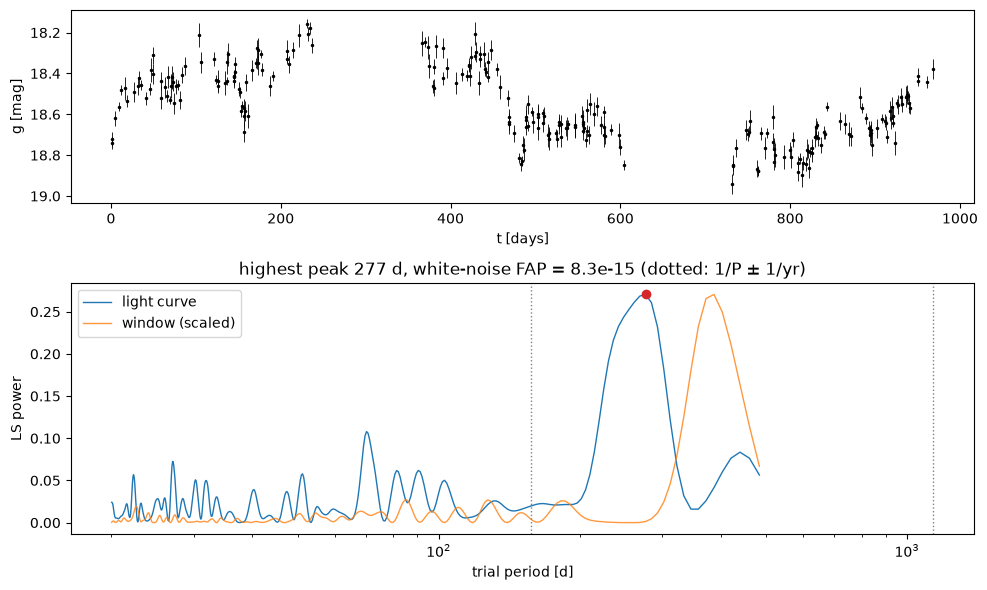

In [2]:
# Part 1: your work here
fmin, fmax = 1/(T/2), 1/20.0
freq = np.arange(fmin, fmax, 1/(10*T)) 
period = 1/freq

ls = LombScargle(t, y, e)
power = ls.power(freq)
win = LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False).power(freq)
win *= power.max() / win.max() 

k = np.argmax(power)
P_pk = period[k]
fap = ls.false_alarm_probability(power[k], minimum_frequency=fmin, maximum_frequency=fmax)
print(f"highest peak: P = {P_pk:.1f} d, power = {power[k]:.3f}, astropy FAP = {fap:.2e}")

fig, ax = plt.subplots(2, 1, figsize=(10, 6), gridspec_kw={'height_ratios': [1, 1.3]})
ax[0].errorbar(t, y, e, fmt='.', ms=3, lw=0.6, color='k')
ax[0].invert_yaxis(); ax[0].set_xlabel('t [days]'); ax[0].set_ylabel('g [mag]')

ax[1].plot(period, power, lw=1, label='light curve')
ax[1].plot(period, win, lw=1, color='C1', alpha=0.8, label='window (scaled)')
for s in (+1, -1):                               # one-year aliases of the top peak
    fa = 1/P_pk + s/365.25
    if fa > 0: ax[1].axvline(1/fa, color='gray', ls=':', lw=1)
ax[1].plot([P_pk], [power[k]], 'o', color='C3')
ax[1].set_xscale('log'); ax[1].set_xlabel('trial period [d]'); ax[1].set_ylabel('LS power')
ax[1].set_title(f'highest peak {P_pk:.0f} d, white-noise FAP = {fap:.1e} (dotted: 1/P ± 1/yr)')
ax[1].legend(); plt.tight_layout(); plt.show()

**ANSWER (a few sentences):**

*What period is the highest peak? Which other peaks are probably aliases of it or of the sampling?* \
The highest peak is at P = 277 days, but it is very broad and covers about 3.5 cycles in T = 970 days, so the period is uncertain by tens of days. Its one-year aliases would sit at about 157 days and 1140 days, but there is no matching peak at 157 d, and 1140 d falls outside the search range. The other peaks seen here at about 68 days are minor and not clearly tied to the signal or the window. \
\
*Why not search beyond $T/2$?* \
We stop at T/2 because fewer than two cycles cannot be distinguished from the mean or a slow trend since the red noise becomes more prevalent. \
\
*What noise model does astropy's false-alarm probability assume?*
Astropy’s FAP assumes independent Gaussian white noise, which is incorrect for a quasar whose variability far exceeds its errors and cannot give evidence for the period. 

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ 0.291 (+0.235 / −0.087) mag, $\tau = $ 206 (+475 / −109) d, $T/\tau = $ 4.694; the exponential kernel beats the squared exponential by $\Delta\ln L = $ 25.3; 31 of 38 held-out points are inside the 68% band.

In [3]:
# Part 2: your work here
from numpy.linalg import LinAlgError
N = t.size
LNS = (np.log(0.01), np.log(3.0)) 
LNT = (np.log(10.0), np.log(4000.0)) 

def kernel(D, sig, tau, kind):
    if kind == 'exp':
        return sig**2 * np.exp(-D / tau)
    return sig**2 * np.exp(-0.5 * (D / tau)**2)

def make_lnpost(t, y, e, kind='exp'):
    D = np.abs(t[:, None] - t[None, :])
    n = t.size
    lo, hi = y.min(), y.max()
    def lnprior(th):
        mu, lns, lnt = th
        if not (lo < mu < hi and LNS[0] < lns < LNS[1] and LNT[0] < lnt < LNT[1]):
            return -np.inf
        return 0.0 
    def lnlike(th):
        mu, lns, lnt = th
        C = kernel(D, np.exp(lns), np.exp(lnt), kind)
        C[np.diag_indices(n)] += e**2
        try:
            cf = cho_factor(C, lower=True)
        except LinAlgError:
            return -np.inf
        r = y - mu
        return -0.5 * r @ cho_solve(cf, r) - np.sum(np.log(np.diag(cf[0]))) - 0.5 * n * np.log(2 * np.pi)
    def lnpost(th):
        lp = lnprior(th)
        return lp + lnlike(th) if np.isfinite(lp) else -np.inf
    return lnpost, lnlike, lnprior

def fit_ml(t, y, e, kind='exp', verbose=False):
    lnpost, _, _ = make_lnpost(t, y, e, kind)
    def nll(th):
        v = lnpost(th)
        return -v if np.isfinite(v) else 1e25
    best, results = None, []
    for tau0 in [20, 100, 500, 2000]:
        for sig0 in [0.1, 0.4]:
            r = minimize(nll, [y.mean(), np.log(sig0), np.log(tau0)], method='Nelder-Mead',
                         options={'xatol': 1e-4, 'fatol': 1e-6, 'maxiter': 2000})
            results.append(r)
            if verbose:
                print(f"  start tau0={tau0:5d} sig0={sig0}: lnL={-r.fun:9.3f}  sigma={np.exp(r.x[1]):.3f}  tau={np.exp(r.x[2]):.0f}")
            if best is None or r.fun < best.fun: best = r
    return best

fit_exp = fit_ml(t, y, e, 'exp', verbose=True)
fit_se  = fit_ml(t, y, e, 'se',  verbose=True)
lnL_exp, lnL_se = -fit_exp.fun, -fit_se.fun
mu_ml, sig_ml, tau_ml = fit_exp.x[0], np.exp(fit_exp.x[1]), np.exp(fit_exp.x[2])
print(f"\nDRW ML: mu={mu_ml:.3f} sigma={sig_ml:.3f} tau={tau_ml:.0f} d lnL={lnL_exp:.2f}")
print(f"SE  ML: mu={fit_se.x[0]:.3f} sigma={np.exp(fit_se.x[1]):.3f} ell={np.exp(fit_se.x[2]):.0f} d lnL={lnL_se:.2f}")
print(f"Delta lnL (exp - SE) = {lnL_exp - lnL_se:.2f}")

  start tau0=   20 sig0=0.1: lnL=  312.919  sigma=0.208  tau=101
  start tau0=   20 sig0=0.4: lnL=  312.919  sigma=0.208  tau=101
  start tau0=  100 sig0=0.1: lnL=  312.919  sigma=0.208  tau=101
  start tau0=  100 sig0=0.4: lnL=  312.919  sigma=0.208  tau=101
  start tau0=  500 sig0=0.1: lnL=  312.919  sigma=0.208  tau=101
  start tau0=  500 sig0=0.4: lnL=  312.919  sigma=0.208  tau=101
  start tau0= 2000 sig0=0.1: lnL=  312.919  sigma=0.208  tau=101
  start tau0= 2000 sig0=0.4: lnL=  312.919  sigma=0.208  tau=101
  start tau0=   20 sig0=0.1: lnL=  287.524  sigma=0.163  tau=10
  start tau0=   20 sig0=0.4: lnL=  287.585  sigma=0.163  tau=10
  start tau0=  100 sig0=0.1: lnL=  287.584  sigma=0.163  tau=10
  start tau0=  100 sig0=0.4: lnL=  287.585  sigma=0.163  tau=10
  start tau0=  500 sig0=0.1: lnL=  287.585  sigma=0.163  tau=10
  start tau0=  500 sig0=0.4: lnL=  287.585  sigma=0.163  tau=10
  start tau0= 2000 sig0=0.1: lnL=  287.585  sigma=0.163  tau=10
  start tau0= 2000 sig0=0.4: lnL

100%|██████████| 4000/4000 [16:26<00:00,  4.05it/s]


autocorr time [steps] (mu, ln sig, ln tau): [42.8 48.  48.8] | steps/tau_int: [94. 83. 82.]
mean acceptance fraction: 0.61
mu: median 1st half 18.545, 2nd half 18.550
ln sigma: median 1st half -1.238, 2nd half -1.233
ln tau: median 1st half 5.313, 2nd half 5.334
mu [mag]     = 18.547 (+0.150 / -0.151)
sigma [mag]  = 0.291 (+0.235 / -0.087)
tau [d]      = 206.179 (+474.950 / -108.641)
T/tau        = 4.694 (+5.228 / -3.273)
ln tau 68% width: 1.94
fraction of samples with tau > 2000 d: 0.041


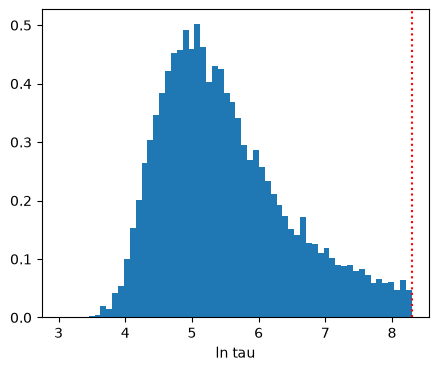

In [4]:
import emcee
lnpost, _, _ = make_lnpost(t, y, e, 'exp')
nw, nd, nsteps, burn = 32, 3, 4000, 1000
rng = np.random.default_rng(457)
np.random.seed(457)
scale = np.array([0.005, 0.05, 0.1])
p0 = np.empty((nw, nd))
for i in range(nw):
    s = scale.copy()
    p0[i] = fit_exp.x + rng.normal(size=nd) * s
    while not np.isfinite(lnpost(p0[i])):
        s *= 0.5
        p0[i] = fit_exp.x + rng.normal(size=nd) * s

sampler = emcee.EnsembleSampler(nw, nd, lnpost)
sampler.run_mcmc(p0, nsteps, progress=True)

# convergence checks
tau_int = sampler.get_autocorr_time(tol=0)
print("autocorr time [steps] (mu, ln sig, ln tau):", np.round(tau_int, 1), "| steps/tau_int:", np.round(nsteps / tau_int, 0))
print("mean acceptance fraction:", sampler.acceptance_fraction.mean().round(2))
ch = sampler.get_chain(discard=burn)
h = ch.shape[0] // 2
for j, nm in enumerate(['mu', 'ln sigma', 'ln tau']):
    print(f"{nm}: median 1st half {np.median(ch[:h, :, j]):.3f}, 2nd half {np.median(ch[h:, :, j]):.3f}")

flat = sampler.get_chain(discard=burn, thin=10, flat=True)
def summ(x):
    lo, m, hi = np.percentile(x, [16, 50, 84])
    return m, hi - m, m - lo
sig_s, tau_s, mu_s = np.exp(flat[:, 1]), np.exp(flat[:, 2]), flat[:, 0]
for nm, x in [('mu [mag]', mu_s), ('sigma [mag]', sig_s), ('tau [d]', tau_s), ('T/tau', T / tau_s)]:
    m, up, dn = summ(x)
    print(f"{nm:12s} = {m:.3f} (+{up:.3f} / -{dn:.3f})")
print("ln tau 68% width:", np.subtract(*np.percentile(flat[:, 2], [84, 16])).round(2))
print("fraction of samples with tau > 2000 d:", (tau_s > 2000).mean().round(3))

plt.figure(figsize=(5, 4)); plt.hist(flat[:, 2], 60, density=True); plt.xlabel('ln tau')
plt.axvline(LNT[1], color='r', ls=':'); plt.show()

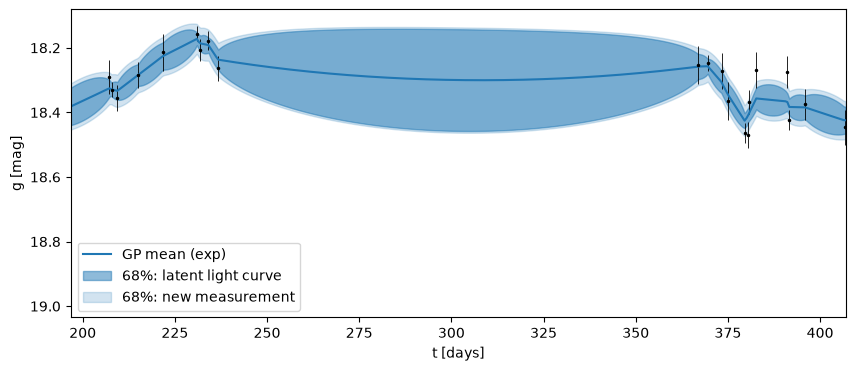

In [5]:
def gp_predict(ts, tr, yr, er, th, kind):
    mu, sig, tau = th[0], np.exp(th[1]), np.exp(th[2])
    C = kernel(np.abs(tr[:, None] - tr[None, :]), sig, tau, kind) + np.diag(er**2)
    cf = cho_factor(C, lower=True)
    Ks = kernel(np.abs(ts[:, None] - tr[None, :]), sig, tau, kind)
    mean = mu + Ks @ cho_solve(cf, yr - mu)
    var = sig**2 - np.einsum('ij,ji->i', Ks, cho_solve(cf, Ks.T))
    return mean, np.sqrt(np.clip(var, 0, None)) 

best_kind, best_fit = ('exp', fit_exp) if lnL_exp >= lnL_se else ('se', fit_se)
i = np.argmax(np.diff(t)) 
tg = np.linspace(t[i] - 40, t[i + 1] + 40, 400)
m, sd_lat = gp_predict(tg, t, y, e, best_fit.x, best_kind)
sd_new = np.sqrt(sd_lat**2 + np.median(e)**2) 

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(t, y, e, fmt='k.', ms=3, lw=0.6)
ax.plot(tg, m, 'C0', label=f'GP mean ({best_kind})')
ax.fill_between(tg, m - sd_lat, m + sd_lat, color='C0', alpha=0.5, label='68%: latent light curve')
ax.fill_between(tg, m - sd_new, m + sd_new, color='C0', alpha=0.2, label='68%: new measurement')
ax.set_xlim(tg[0], tg[-1]); ax.invert_yaxis()
ax.set_xlabel('t [days]'); ax.set_ylabel('g [mag]'); ax.legend(); plt.show()

In [6]:
def draw_blocks(t, seed=457, nblk=4, L=30, sep=60, min_pts=5, gap_thresh=90):
    rng = np.random.default_rng(seed)
    edges = np.r_[0, np.where(np.diff(t) > gap_thresh)[0] + 1, t.size]
    seasons = [(t[a], t[b - 1]) for a, b in zip(edges[:-1], edges[1:])]
    while True:
        blocks = []
        for _ in range(nblk):
            lo, hi = seasons[rng.integers(len(seasons))]
            s = rng.uniform(lo, hi - L)
            blocks.append((s, s + L))
        blocks.sort()
        ok = all(blocks[j + 1][0] - blocks[j][1] >= sep for j in range(nblk - 1))
        inb = [(t >= a) & (t <= b) for a, b in blocks]
        if ok and min(m.sum() for m in inb) >= min_pts:
            return blocks, np.any(inb, axis=0), seasons

blocks, mask, seasons = draw_blocks(t)
print("seasons:", [(round(a), round(b)) for a, b in seasons])   # should show 3
print("blocks:", [(round(a), round(b)) for a, b in blocks], "| held out:", mask.sum())

def holdout_eval(kind):
    tr, yr, er = t[~mask], y[~mask], e[~mask]
    fit = fit_ml(tr, yr, er, kind)
    mean, sd_lat = gp_predict(t[mask], tr, yr, er, fit.x, kind)
    sd_pred = np.sqrt(sd_lat**2 + e[mask]**2) 
    inside = np.abs(y[mask] - mean) < sd_pred
    r2 = 1 - np.sum((y[mask] - mean)**2) / np.sum((y[mask] - yr.mean())**2)
    print(f"{kind:4s}: held out {mask.sum()}, inside 68% band {inside.sum()} ({inside.mean():.2f}), "
          f"R^2 vs training mean = {r2:.3f}, sigma={np.exp(fit.x[1]):.3f}, scale={np.exp(fit.x[2]):.0f} d")
    return mean, sd_pred

for kind in ['exp', 'se']:
    holdout_eval(kind)

seasons: [(1, 237), (367, 604), (731, 969)]
blocks: [(2, 32), (422, 452), (567, 597), (787, 817)] | held out: 38
exp : held out 38, inside 68% band 31 (0.82), R^2 vs training mean = 0.884, sigma=0.209, scale=95 d
se  : held out 38, inside 68% band 26 (0.68), R^2 vs training mean = 0.720, sigma=0.168, scale=10 d


**FINAL ANSWER:**

*Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.* \
Uniform in ln sigma and ln tau treats every decade of a scale parameter equally. sigma < 0.01 mag is below the photometric errors, sigma > 3 mag is far beyond any quasar rms, tau < 10 d is a few cadences, and tau > 4000 d is about 4T. The posterior has a long tail toward large tau but only 4.4% of samples lie above 2000 d, so the 68% interval is data-driven. \
\
*Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.* \
All 8 starting points converged to the same maximum of σ = 0.208 mag, τ = 101 d, and ln L = 312.9. I used multiple starts because the σ–τ ridge and flat long-τ region can stop an optimizer early. With emcee, I get σ = 0.29 (+0.24/−0.09) mag, τ = 206 (+495/−107) d and T/τ = 4.7 (+5.1/−3.3). Convergence checks: the autocorrelation time is about 44 steps , the acceptance fraction is 0.61, and the half-chain medians agree. Tau is hard to measure because the baseline holds only a few independent correlation times, which gives the skewed, asymmetric interval. \
\
*Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?* \
The exponential kernel has the higher maximum ln L of 312.9 vs. 287.6, better by Δ ln L = 25.3. A quasar light curve is therefore continuous but rough on these timescales, which the infinitely smooth SE kernel cannot match. \
\
*Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.* \
The plot spans the largest seasonal gap with the DRW. The dark band is the 68% interval for the latent, noise-free light curve, and the light band adds measurement noise for a new measurement. This matters because data points scatter by their own errors around the latent curve, so they should be compared with the wider band. \
\
*Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?* \
I held out 38 points in four 30-day blocks and refit on the rest. The DRW has 31 of 38 inside the 68% band and R^2 = 0.88 against the training mean, and the SE kernel has 26 of 38 and R^2 = 0.72. The DRW band looks reasonable but mildly conservative, and the SE band’s nominal coverage is misleading with poor predictions. 

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01

Suggested p-value: 0.10

DRW ML: mu=18.546 sigma=0.208 tau=101 d
observed LS max power = 0.270 (P = 277 d); astropy FAP = 8.3e-15
empirical p (LS peak height):        0.7841   (2000 sims)
observed max dchi2 (DRW+sinusoid) = 9.0 at P = 20 d
empirical p (DRW+sinusoid dchi2):    0.6492
tau =    98 d (16th pct), sigma = 0.204: p_LS = 0.7836, p_DRW+sin = 0.6567
tau =   681 d (84th pct), sigma = 0.521: p_LS = 0.7871, p_DRW+sin = 0.5897


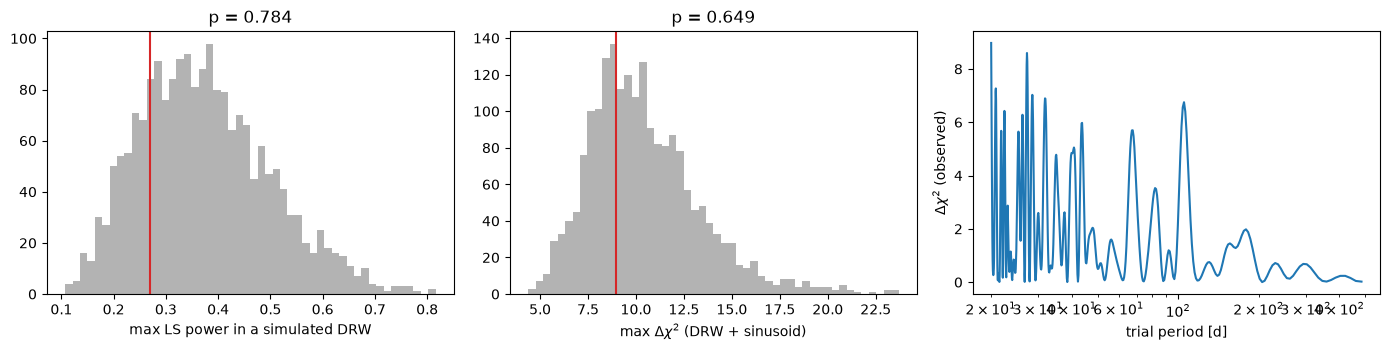

best P = 20 d (dchi2 - 1 range: 20 to 20 d), amplitude = 0.021 mag (68%: 0.016 to 0.029)
VERDICT by the pre-registered rule: no evidence for a period (p = 0.6492, threshold 0.1)


In [7]:
# Part 3: your work here
from scipy.linalg import solve_triangular
ALPHA, NSIM = 0.10, 2000 # must match the markdown cell above
D = np.abs(t[:, None] - t[None, :])
F = freq.size
lnpost_full, _, _ = make_lnpost(t, y, e, 'exp')

def sim_lcs(mu, sig, tau, nsim, rng):
    Cs = sig**2 * np.exp(-D / tau) + 1e-8 * sig**2 * np.eye(N)
    Lc = np.linalg.cholesky(Cs)
    return (mu + Lc @ rng.standard_normal((N, nsim))
            + e[:, None] * rng.standard_normal((N, nsim)))

def ls_max(Y):
    return np.array([LombScargle(t, Y[:, j], e).power(freq).max() for j in range(Y.shape[1])])

class GLSScan:
    def __init__(self, sig, tau):
        C = sig**2 * np.exp(-D / tau) + np.diag(e**2)
        self.Lc = np.linalg.cholesky(C)
        arg = 2 * np.pi * freq[:, None] * t[None, :]
        X = np.stack([np.ones((F, N)), np.cos(arg), np.sin(arg)], axis=-1) 
        Xt = solve_triangular(self.Lc, X.transpose(1, 0, 2).reshape(N, F * 3), lower=True)
        self.Xt = Xt.reshape(N, F, 3).transpose(1, 0, 2)  
        self.A = np.einsum('fnk,fnl->fkl', self.Xt, self.Xt) 
        self.Ainv = np.linalg.inv(self.A)
    def dchi2(self, Y):
        """Delta chi^2 (constant-mean model minus mean+sinusoid), shape (F, ncols)."""
        Yt = solve_triangular(self.Lc, Y, lower=True)
        B = np.matmul(self.Xt.transpose(0, 2, 1), Yt)  
        quad = np.einsum('fks,fkl,fls->fs', B, self.Ainv, B)
        const = B[:, 0, :]**2 / self.A[:, 0, 0][:, None]
        return quad - const

def run_null(mu, sig, tau, nsim=NSIM, seed=2026):
    rng = np.random.default_rng(seed)
    Ysim = sim_lcs(mu, sig, tau, nsim, rng)
    ls_sim = ls_max(Ysim)
    p_ls = (1 + np.sum(ls_sim >= power.max())) / (nsim + 1)
    scan = GLSScan(sig, tau)
    dchi = scan.dchi2(np.column_stack([y, Ysim]))
    obs, sim = dchi[:, 0].max(), dchi[:, 1:].max(axis=0)
    p_gls = (1 + np.sum(sim >= obs)) / (nsim + 1)
    return dict(p_ls=p_ls, ls_sim=ls_sim, p_gls=p_gls, gls_obs=obs, gls_sim=sim,
                dchi_obs=dchi[:, 0], scan=scan)

main = run_null(mu_ml, sig_ml, tau_ml)
print(f"DRW ML: mu={mu_ml:.3f} sigma={sig_ml:.3f} tau={tau_ml:.0f} d")
print(f"observed LS max power = {power.max():.3f} (P = {period[np.argmax(power)]:.0f} d); astropy FAP = {fap:.1e}")
print(f"empirical p (LS peak height):        {main['p_ls']:.4f}   ({NSIM} sims)")
print(f"observed max dchi2 (DRW+sinusoid) = {main['gls_obs']:.1f} at P = {period[np.argmax(main['dchi_obs'])]:.0f} d")
print(f"empirical p (DRW+sinusoid dchi2):    {main['p_gls']:.4f}")

tau_lo, tau_hi = np.percentile(tau_s, [16, 84])
def profile_sigma(tau_fix):
    nll = lambda p: -lnpost_full([p[0], p[1], np.log(tau_fix)]) if np.isfinite(lnpost_full([p[0], p[1], np.log(tau_fix)])) else 1e25
    r = minimize(nll, [mu_ml, np.log(sig_ml)], method='Nelder-Mead')
    return r.x[0], np.exp(r.x[1])
for lab, tau_fix in [('16th pct', tau_lo), ('84th pct', tau_hi)]:
    mu_f, sig_f = profile_sigma(tau_fix)
    r = run_null(mu_f, sig_f, tau_fix)
    print(f"tau = {tau_fix:5.0f} d ({lab}), sigma = {sig_f:.3f}: p_LS = {r['p_ls']:.4f}, p_DRW+sin = {r['p_gls']:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(main['ls_sim'], 50, color='0.7'); ax[0].axvline(power.max(), color='C3')
ax[0].set_xlabel('max LS power in a simulated DRW'); ax[0].set_title(f"p = {main['p_ls']:.3f}")
ax[1].hist(main['gls_sim'], 50, color='0.7'); ax[1].axvline(main['gls_obs'], color='C3')
ax[1].set_xlabel(r'max $\Delta\chi^2$ (DRW + sinusoid)'); ax[1].set_title(f"p = {main['p_gls']:.3f}")
ax[2].plot(period, main['dchi_obs']); ax[2].set_xscale('log')
ax[2].set_xlabel('trial period [d]'); ax[2].set_ylabel(r'$\Delta\chi^2$ (observed)')
plt.tight_layout(); plt.show()

kb = np.argmax(main['dchi_obs']); Pb = period[kb]
Xt_b, Ainv_b = main['scan'].Xt[kb], main['scan'].Ainv[kb]
Yt = solve_triangular(main['scan'].Lc, y, lower=True)
theta = Ainv_b @ (Xt_b.T @ Yt) 
amp = np.hypot(theta[1], theta[2])
th_s = np.random.default_rng(1).multivariate_normal(theta, Ainv_b, 20000)
amp_s = np.hypot(th_s[:, 1], th_s[:, 2])
inside = main['dchi_obs'] > main['dchi_obs'].max() - 1 
lo_i = hi_i = kb
while lo_i > 0 and inside[lo_i - 1]: lo_i -= 1
while hi_i < F - 1 and inside[hi_i + 1]: hi_i += 1
print(f"best P = {Pb:.0f} d (dchi2 - 1 range: {period[hi_i]:.0f} to {period[lo_i]:.0f} d), "
      f"amplitude = {amp:.3f} mag (68%: {np.percentile(amp_s,16):.3f} to {np.percentile(amp_s,84):.3f})")
print("VERDICT by the pre-registered rule:", "PERIODIC" if main['p_gls'] < ALPHA else "no evidence for a period",
      f"(p = {main['p_gls']:.4f}, threshold {ALPHA})")

**ANSWER (the decision rule first, then the verdict):**

My decision rule was to claim a period only if the empirical p-value of the DRW and sinusoid max Δχ² is below 0.10, using 2000 simulated DRW light curves at my Part 2 maximum-likelihood μ, σ and τ. Some data fail this rule, and the empirical p-value is 0.65 for the DRW & sinusoid statistic and 0.78 for the Lomb-Scargle peak height, so about two thirds of pure-DRW light curves with no period at all produce a peak at least as tall as mine. Astropy’s FAP of 8×10⁻¹⁵ is wrong by about 14 orders of magnitude because it assumes white noise, while the red noise from the DRW produces tall slow peaks. The best DRW + sinusoid period is 20 d, and the 277 d peak does not stand out once the red noise is modeled, so there is no evidence for a period and I do not quote one. The team should not announce a binary candidate on this evidence.

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


AI period search: P = 274.7 +/- 4.6 d, power 0.271, FAP 7.9e-15
AI SE fit: sigma=0.158, ell=9.4 d, lnL=287.86

[1] astropy FAP = 7.9e-15; empirical p (LS) = 0.7841; empirical p (DRW+sin) = 0.6492
    astropy's 1% power threshold = 0.077; 99th percentile of pure-DRW maxima = 0.688
    fraction of pure-DRW (NO period) curves above astropy's 1% threshold = 1.00 (nominal 0.01)


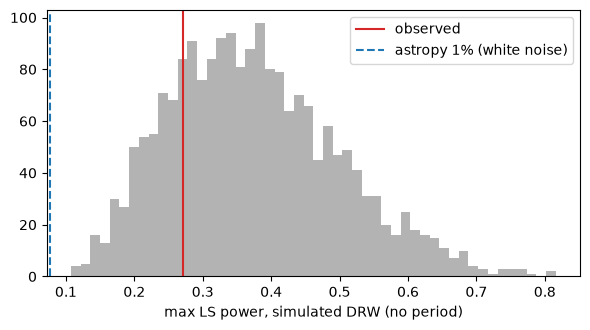


[2] lnL: DRW 312.92 vs AI's SE 287.86 (Delta = 25.06); same number of parameters

[3] same fixed hyperparameters, two CV designs:
    SE (AI fit)   random 5-fold: R2=0.876, cover=0.61 | 4 blocks: R2=0.692, cover=0.74
    DRW (Part 2)  random 5-fold: R2=0.888, cover=0.69 | 4 blocks: R2=0.883, cover=0.79


In [8]:
# Part 4: your work here
f_ai = np.linspace(1 / (T / 2), 1 / 20, 6000)
ls_ai = LombScargle(t, y, e)
p_ai = ls_ai.power(f_ai); k_ai = np.argmax(p_ai); P_ai = 1 / f_ai[k_ai]
fap_ai = ls_ai.false_alarm_probability(p_ai[k_ai], minimum_frequency=f_ai[0], maximum_frequency=f_ai[-1])
th_ai = ls_ai.model_parameters(f_ai[k_ai]); amp_ai = np.hypot(th_ai[1], th_ai[2])
resid_ai = y - ls_ai.model(t, f_ai[k_ai])
P_err_ai = P_ai**2 * np.sqrt(6 / t.size) * resid_ai.std() / (np.pi * T * amp_ai)   # AI's period-error formula
print(f"AI period search: P = {P_ai:.1f} +/- {P_err_ai:.1f} d, power {p_ai[k_ai]:.3f}, FAP {fap_ai:.1e}")

def nll_ai(p):                                   # the AI's SE likelihood: no bounds, single start
    mu, ls_, ll = p
    K = np.exp(2 * ls_) * np.exp(-0.5 * ((t[:, None] - t[None, :]) / np.exp(ll))**2) + np.diag(e**2)
    try: c = cho_factor(K, lower=True)
    except np.linalg.LinAlgError: return 1e10
    r = y - mu
    return 0.5 * r @ cho_solve(c, r) + np.log(np.diag(c[0])).sum() + 0.5 * y.size * np.log(2 * np.pi)
res_ai = minimize(nll_ai, [y.mean(), np.log(y.std()), np.log(30.)], method='Nelder-Mead',
                  options=dict(xatol=1e-4, fatol=1e-6, maxiter=1500))
lnL_ai_se = -res_ai.fun
print(f"AI SE fit: sigma={np.exp(res_ai.x[1]):.3f}, ell={np.exp(res_ai.x[2]):.1f} d, lnL={lnL_ai_se:.2f}")

# Error 1: 
lev01 = ls_ai.false_alarm_level(0.01, minimum_frequency=f_ai[0], maximum_frequency=f_ai[-1])
sim_max = main['ls_sim']                         # max LS power of each pure-DRW light curve (Part 3)
print(f"\n[1] astropy FAP = {fap_ai:.1e}; empirical p (LS) = {main['p_ls']:.4f}; empirical p (DRW+sin) = {main['p_gls']:.4f}")
print(f"    astropy's 1% power threshold = {lev01:.3f}; 99th percentile of pure-DRW maxima = {np.percentile(sim_max, 99):.3f}")
print(f"    fraction of pure-DRW (NO period) curves above astropy's 1% threshold = {np.mean(sim_max > lev01):.2f} (nominal 0.01)")
plt.figure(figsize=(6, 3.4)); plt.hist(sim_max, 50, color='0.7')
plt.axvline(p_ai[k_ai], color='C3', label='observed'); plt.axvline(lev01, color='C0', ls='--', label="astropy 1% (white noise)")
plt.xlabel('max LS power, simulated DRW (no period)'); plt.legend(); plt.tight_layout(); plt.show()

# Error 2: 
print(f"\n[2] lnL: DRW {lnL_exp:.2f} vs AI's SE {lnL_ai_se:.2f} (Delta = {lnL_exp - lnL_ai_se:.2f}); same number of parameters")

# Error 3: 
def stats(mean, sd_lat, idx, ref):
    sd = np.sqrt(sd_lat**2 + e[idx]**2)
    return 1 - np.sum((y[idx] - mean)**2) / np.sum((y[idx] - ref)**2), np.mean(np.abs(y[idx] - mean) < sd)

def random_cv(kind, th, nfold=5, seed=1): # the AI's scheme
    folds = np.random.default_rng(seed).permutation(t.size) % nfold
    mean, sdl = np.empty(t.size), np.empty(t.size)
    for kf in range(nfold):
        te = folds == kf
        mean[te], sdl[te] = gp_predict(t[te], t[~te], y[~te], e[~te], th, kind)
    return stats(mean, sdl, np.arange(t.size), y.mean())

def block_cv_fixed(kind, th): 
    mean, sdl = gp_predict(t[mask], t[~mask], y[~mask], e[~mask], th, kind)
    return stats(mean, sdl, np.where(mask)[0], y[~mask].mean())

print("\n[3] same fixed hyperparameters, two CV designs:")
for name, kind, th in [('SE (AI fit)', 'se', res_ai.x), ('DRW (Part 2)', 'exp', fit_exp.x)]:
    r2r, cr = random_cv(kind, th); r2b, cb = block_cv_fixed(kind, th)
    print(f"    {name:13s} random 5-fold: R2={r2r:.3f}, cover={cr:.2f} | 4 blocks: R2={r2b:.3f}, cover={cb:.2f}")

**REFEREE REPORT:**

1. The AI calls its peak “highly significant” using astropy’s FAP, which assumes independent noise with the quoted errors, but a quasar’s red-noise variability is much larger than those errors, so slow, tall peaks are common with no period at all. My simulations of pure DRW light curves give an empirical p = 0.78 for the LS peak height and 0.65 for the DRW + sinusoid statistic.
2. The AI asserts that quasar variability is smooth and uses an SE kernel as the standard default without comparing it to a DRW. With the same number of parameters, the DRW has the higher ln L and predicts the held-out blocks better. The correct treatment is to fit both kernels and compare ln L, which favors the DRW.
3. Every held-out epoch has training points only a few days away, and the AI’s hyperparameters were fit on all the data including the held-out points, so the test mostly measures interpolation between near neighbours and does not stress the model. With identical fixed hyperparameters, random folds cannot discriminate between the kernels. The correct treatment is blocked hold-out inside a season, refitting on the training set only.

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [9]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF18aajtwea: 744 g-band detections from the live API
ZTF18aajtwea: MJD 58287.3 to 61059.5 (7.6 yr); the last detection is MJD 61059.5; today is MJD 61342


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


744 detections -> 523 nightly means over 2772 d; median spacing 2.0 d; 7 gaps > 60 d: [136, 108, 73, 73, 96, 156, 119]
last detection 2026-01-19, 283 d before today
DRW ML: mu=16.617 sigma=0.123 tau=904 d, T/tau=3.1, lnL=1196.3
highest LS peak: P = 433 d, power 0.300, astropy FAP = 6.7e-38
max dchi2 (DRW+sinusoid) = 14.5 at P = 24 d
empirical p: LS height = 0.5135, DRW+sinusoid = 0.2088
tau =   452 d, sigma = 0.089: p_LS = 0.5514, p_DRW+sin = 0.2498
tau =  1808 d, sigma = 0.172: p_LS = 0.4745, p_DRW+sin = 0.1948
VERDICT by the pre-registered rule: no evidence for a period (p = 0.2088, threshold 0.1)


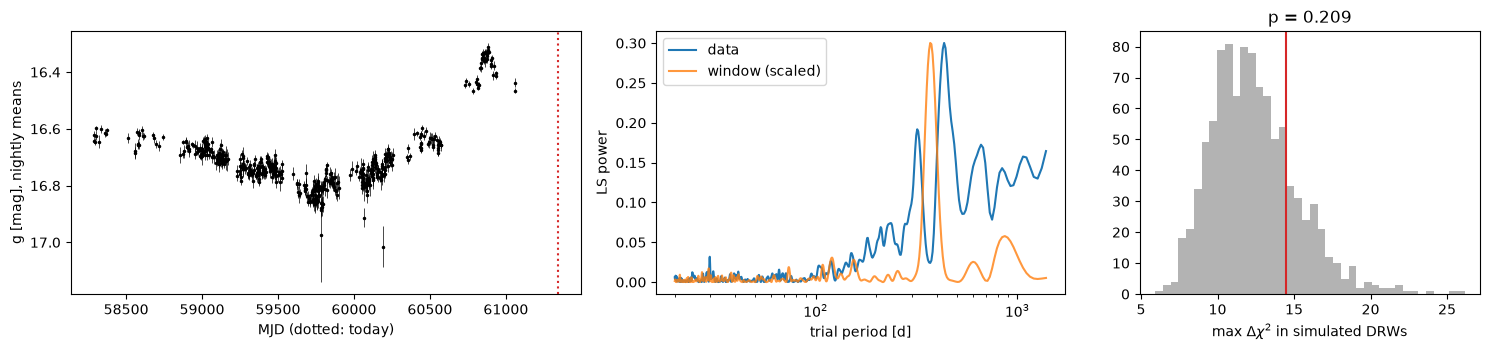

In [11]:
# Part 5: your work here

ALPHA5, NSIM5 = 0.10, 1000 
night = np.floor(mjd).astype(int)
_, inv = np.unique(night, return_inverse=True)
w = 1 / merr**2
sw = np.bincount(inv, w)
tq = np.bincount(inv, w * mjd) / sw
yq = np.bincount(inv, w * mag) / sw
eq = 1 / np.sqrt(sw)
mjd0 = tq.min(); tq = tq - mjd0
Nq, Tq = tq.size, tq.max()
gaps = np.diff(tq); big = np.where(gaps > 60)[0]
print(f"{mjd.size} detections -> {Nq} nightly means over {Tq:.0f} d; median spacing {np.median(gaps):.1f} d; "
      f"{big.size} gaps > 60 d: {[int(gaps[i]) for i in big]}")
print(f"last detection {Time(mjd.max(), format='mjd').iso[:10]}, {Time.now().mjd - mjd.max():.0f} d before today")

fq = np.arange(1 / (Tq / 2), 1 / 20.0, 1 / (10 * Tq)); perq = 1 / fq

fitq = fit_ml(tq, yq, eq, 'exp')
mu_q, sig_q, tau_q = fitq.x[0], np.exp(fitq.x[1]), np.exp(fitq.x[2])
print(f"DRW ML: mu={mu_q:.3f} sigma={sig_q:.3f} tau={tau_q:.0f} d, T/tau={Tq / tau_q:.1f}, lnL={-fitq.fun:.1f}")

lsq = LombScargle(tq, yq, eq)
pw = lsq.power(fq); kq = np.argmax(pw)
winq = LombScargle(tq, np.ones_like(yq), fit_mean=False, center_data=False).power(fq)
winq *= pw.max() / winq.max()
print(f"highest LS peak: P = {perq[kq]:.0f} d, power {pw[kq]:.3f}, "
      f"astropy FAP = {lsq.false_alarm_probability(pw[kq], minimum_frequency=fq.min(), maximum_frequency=fq.max()):.1e}")

class GLSq:
    def __init__(self, tt, ee, fr, sig, tau):
        n = tt.size
        C = sig**2 * np.exp(-np.abs(tt[:, None] - tt[None, :]) / tau) + np.diag(ee**2)
        self.Lc = np.linalg.cholesky(C)
        arg = 2 * np.pi * fr[:, None] * tt[None, :]
        X = np.stack([np.ones((fr.size, n)), np.cos(arg), np.sin(arg)], axis=-1)        # (F, N, 3)
        Xt = solve_triangular(self.Lc, X.transpose(1, 0, 2).reshape(n, -1), lower=True)
        self.Xt = Xt.reshape(n, fr.size, 3).transpose(1, 0, 2)
        self.A = np.einsum('fnk,fnl->fkl', self.Xt, self.Xt)
        self.Ainv = np.linalg.inv(self.A)
    def dchi2(self, Y):
        B = np.matmul(self.Xt.transpose(0, 2, 1), solve_triangular(self.Lc, Y, lower=True))
        return np.einsum('fks,fkl,fls->fs', B, self.Ainv, B) - B[:, 0, :]**2 / self.A[:, 0, 0][:, None]

def sim_q(mu, sig, tau, nsim, rng):
    Lc = np.linalg.cholesky(sig**2 * np.exp(-np.abs(tq[:, None] - tq[None, :]) / tau) + 1e-8 * sig**2 * np.eye(Nq))
    return mu + Lc @ rng.standard_normal((Nq, nsim)) + eq[:, None] * rng.standard_normal((Nq, nsim))

def p_values(mu, sig, tau, nsim=NSIM5, seed=5):
    Ys = sim_q(mu, sig, tau, nsim, np.random.default_rng(seed))
    ls_sim = np.array([LombScargle(tq, Ys[:, j], eq).power(fq).max() for j in range(nsim)])
    dchi = GLSq(tq, eq, fq, sig, tau).dchi2(np.column_stack([yq, Ys]))
    obs, sim = dchi[:, 0].max(), dchi[:, 1:].max(axis=0)
    return dict(p_ls=(1 + np.sum(ls_sim >= pw.max())) / (nsim + 1),
                p_gls=(1 + np.sum(sim >= obs)) / (nsim + 1),
                obs=obs, sim=sim, dchi_obs=dchi[:, 0])

res = p_values(mu_q, sig_q, tau_q)
print(f"max dchi2 (DRW+sinusoid) = {res['obs']:.1f} at P = {perq[np.argmax(res['dchi_obs'])]:.0f} d")
print(f"empirical p: LS height = {res['p_ls']:.4f}, DRW+sinusoid = {res['p_gls']:.4f}")

lnpost_q, _, _ = make_lnpost(tq, yq, eq, 'exp')
for f in (0.5, 2.0):
    tf = tau_q * f
    def nll(p):
        v = lnpost_q([p[0], p[1], np.log(tf)])
        return -v if np.isfinite(v) else 1e25
    r = minimize(nll, [mu_q, np.log(sig_q)], method='Nelder-Mead')
    rr = p_values(r.x[0], np.exp(r.x[1]), tf)
    print(f"tau = {tf:5.0f} d, sigma = {np.exp(r.x[1]):.3f}: p_LS = {rr['p_ls']:.4f}, p_DRW+sin = {rr['p_gls']:.4f}")

print("VERDICT by the pre-registered rule:", "PERIODIC" if res['p_gls'] < ALPHA5 else "no evidence for a period",
      f"(p = {res['p_gls']:.4f}, threshold {ALPHA5})")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={'width_ratios': [1.5, 1.2, 1]})
ax[0].errorbar(tq + mjd0, yq, eq, fmt='.', ms=3, lw=0.5, color='k'); ax[0].invert_yaxis()
ax[0].axvline(Time.now().mjd, color='C3', ls=':'); ax[0].set_xlabel('MJD (dotted: today)'); ax[0].set_ylabel('g [mag], nightly means')
ax[1].plot(perq, pw, label='data'); ax[1].plot(perq, winq, color='C1', alpha=0.8, label='window (scaled)')
ax[1].set_xscale('log'); ax[1].set_xlabel('trial period [d]'); ax[1].set_ylabel('LS power'); ax[1].legend()
ax[2].hist(res['sim'], 40, color='0.7'); ax[2].axvline(res['obs'], color='C3')
ax[2].set_xlabel(r'max $\Delta\chi^2$ in simulated DRWs'); ax[2].set_title(f"p = {res['p_gls']:.3f}")
plt.tight_layout(); plt.show()

**ANSWER (the criterion first, then the result):**

I would call this quasar periodic only if the empirical p-value of the DRW + sinusoid max Δχ² is below 0.10. The result is p = 0.21, so there is no evidence for a period, even though the highest LS peak is at 433 days. That peak sits near the one-year peak of the window function, and its large amplitude comes from the slow rise and fall of the light curve. This light curve differs from my simulated one in that it spans 7.6 years with seven gaps longer than 60 days. Since its last detection is 282 days ago, any claimed period cannot be tested against recent data. With a week more of time I would add the r-band light curve and check whether the same period appears, inject sinusoids at this cadence to measure my detection power, and add a free error-scaling term.

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

As with previous labs, I used Claude's Sonnet 5.5 AI to generate some boilerplate code for this lab, particularly for the more mathematical helper functions (emcee walkers) where there were additional parameters and syntax I wanted to check on. Claude also contributed to make the graphs cleaner for the data they could show and helped format the fstring outputs to be more readable. In this lab, Claude has a greater hand in checking over my responses since I felt like this lab had a heavier emphasis on reasoning and justifications than previous labs. This means that AI had a greater hand in the final submission of this lab than it had in previous ones, but the first round of exploration was mine. As always, the responses and analysis I had for each question were my own, but may have been proofread by AI. 
If you notice that this appendix is very similar to the ones submitted on the previous labs, that is a choice made intentionally, since AI was used the same way on both labs.

**REFLECTION:**

The Part 1 peak at 277 days had an astropy false-alarm probability of 8×10⁻¹⁵, and if I had not checked it against the red-noise null, I would have reported a highly significant period for a quasar whose light curve is just a damped random walk. As a result, I would have been wrong by about 14 orders of magnitude and would have recommended a binary candidate.

**VERIFICATION PLAN:**

Before trusting the Part 2 numbers, I checked that all eight starting points converged to the same maximum, that the Cholesky log-determinant is used throughout, and that the emcee chain was about 90 autocorrelation times long with matching half-chain medians. This matters because the likelihood has a σ–τ ridge and a nearly flat region at large τ, where Nelder–Mead can stop early and report a point that depends on where it started. Failure would have looked like different ln L values or different (σ, τ) from different starts. That would mean a local optimum or a premature stop. 